<a href="https://colab.research.google.com/github/nnthaonguyen0909-cloud/analog-krongno/blob/main/analog_krongno.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import os, glob, zipfile

os.makedirs("data", exist_ok=True)
for zpath in glob.glob("/content/*.zip"):
    with zipfile.ZipFile(zpath) as f:
        f.extractall("data")
print(sorted(glob.glob("data/*")))

['data/LDEM_128.IMG', 'data/LDEM_128.IMG.1', 'data/LDEM_128.IMG.2', 'data/LDEM_128.LBL', 'data/LDEM_128.LBL.1', 'data/LDEM_128.LBL.2', 'data/krongno_dem.tif', 'data/n10e105.hgt', 'data/n10e105.num', 'data/n10e105.swb', 'data/n12e107.hgt', 'data/n12e107.num', 'data/n12e107.swb', 'data/n12e108.hgt', 'data/n12e108.num', 'data/n12e108.swb']


In [32]:
import rasterio
from rasterio.merge import merge

def mosaic(tile_paths, out_path):
    """Merge DEM tiles into one GeoTIFF."""
    srcs = [rasterio.open(p) for p in tile_paths]
    arr, transform = merge(srcs)
    meta = srcs[0].meta.copy()
    meta.update(driver="GTiff", height=arr.shape[1], width=arr.shape[2], transform=transform)
    for s in srcs:
        s.close()
    with rasterio.open(out_path, "w", **meta) as dst:
        dst.write(arr)

mosaic(["data/n12e107.hgt", "data/n12e108.hgt"], "data/krongno_dem.tif")
print("done")

done


In [33]:
import numpy as np, rasterio
from rasterio.windows import from_bounds
from scipy.ndimage import uniform_filter
from scipy.stats import wasserstein_distance

R = {"earth": 6371000.0, "moon": 1737400.0, "mars": 3396190.0}  # mean radius (m)
HALF_KM = 25  # 50 x 50 km window, same for all sites

def load_patch(path, lat, lon, half_km, body):
    """Read a square DEM window centered on (lat, lon)."""
    r = R[body]
    dlat = np.degrees(half_km * 1000 / r)
    dlon = dlat / np.cos(np.radians(lat))
    with rasterio.open(path) as src:
        if src.bounds.left >= 0 and lon < 0:  # DEM uses 0-360 longitudes
            lon += 360
        win = from_bounds(lon - dlon, lat - dlat, lon + dlon, lat + dlat, src.transform)
        z = src.read(1, window=win, masked=True).astype("float64").filled(np.nan)
        rx, ry = src.res
    dx = np.radians(rx) * r * np.cos(np.radians(lat))  # pixel width (m)
    dy = np.radians(ry) * r                            # pixel height (m)
    return z, dx, dy

def block_mean(z, dx, dy, target=200.0):
    """Aggregate pixels to a common ~200 m resolution."""
    f = max(1, int(round(target / dx)))
    h, w = (z.shape[0] // f) * f, (z.shape[1] // f) * f
    z = z[:h, :w].reshape(h // f, f, w // f, f)
    return np.nanmean(z, axis=(1, 3)), dx * f, dy * f

def features(z, dx, dy):
    """Slope (degrees) and local roughness (3x3 elevation std)."""
    z = np.where(np.isnan(z), np.nanmean(z), z)
    gy, gx = np.gradient(z, dy, dx)
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))
    m, m2 = uniform_filter(z, 3), uniform_filter(z**2, 3)
    rough = np.sqrt(np.clip(m2 - m**2, 0, None))
    return {"slope": slope.ravel(), "rough": rough.ravel()}

def dist(fa, fb):
    """Mean normalized Wasserstein distance across features."""
    out = []
    for k in ("slope", "rough"):
        s = np.std(np.concatenate([fa[k], fb[k]])) + 1e-9
        out.append(wasserstein_distance(fa[k], fb[k]) / s)
    return float(np.mean(out))

In [34]:
earth_sites = {
    "KrongNo_Earth": ("data/krongno_dem.tif", 12.396, 107.931, "earth"),
    "Control_Earth": ("data/n10e105.hgt",     10.5,   105.5,   "earth"),
}

F = {}
for name, (path, la, lo, body) in earth_sites.items():
    z, dx, dy = load_patch(path, la, lo, HALF_KM, body)
    z, dx, dy = block_mean(z, dx, dy)
    F[name] = features(z, dx, dy)
    print(f"{name}: grid {z.shape}, pixel ~{dx:.0f} m, "
          f"elev {np.nanmin(z):.0f} to {np.nanmax(z):.0f} m, "
          f"median slope {np.median(F[name]['slope']):.2f} deg, "
          f"median roughness {np.median(F[name]['rough']):.2f} m")

print("Krong No vs control distance:", round(dist(F["KrongNo_Earth"], F["Control_Earth"]), 3))

KrongNo_Earth: grid (231, 236), pixel ~211 m, elev 304 to 1568 m, median slope 3.38 deg, median roughness 12.33 m
Control_Earth: grid (231, 235), pixel ~213 m, elev -10 to 18 m, median slope 0.29 deg, median roughness 1.15 m
Krong No vs control distance: 1.177


In [35]:
!wget -q --show-progress -P data https://imbrium.mit.edu/DATA/LOLA_GDR/CYLINDRICAL/IMG/LDEM_128.LBL
!wget -q --show-progress -P data https://imbrium.mit.edu/DATA/LOLA_GDR/CYLINDRICAL/IMG/LDEM_128.IMG
!ls -lh data/LDEM_128.*

LDEM_128.LBL.3      100%[===================>]   5.01K  --.-KB/s    in 0s      
LDEM_128.IMG.3      100%[===================>]   1.98G  32.5MB/s    in 60s     
-rw-r--r-- 1 root root 2.0G Aug 30  2017 data/LDEM_128.IMG
-rw-r--r-- 1 root root 2.0G Aug 30  2017 data/LDEM_128.IMG.1
-rw-r--r-- 1 root root 2.0G Aug 30  2017 data/LDEM_128.IMG.2
-rw-r--r-- 1 root root 2.0G Aug 30  2017 data/LDEM_128.IMG.3
-rw-r--r-- 1 root root 5.1K Aug 31  2017 data/LDEM_128.LBL
-rw-r--r-- 1 root root 5.1K Aug 31  2017 data/LDEM_128.LBL.1
-rw-r--r-- 1 root root 5.1K Aug 31  2017 data/LDEM_128.LBL.2
-rw-r--r-- 1 root root 5.1K Aug 31  2017 data/LDEM_128.LBL.3


In [36]:
import rasterio
with rasterio.open("data/LDEM_128.LBL") as s:
    print("shape:", s.shape, "| res:", s.res)
    print("bounds:", s.bounds)
    print("dtype:", s.dtypes, "| nodata:", s.nodata)
    print("scale/offset:", s.scales, s.offsets)

shape: (23040, 46080) | res: (236.901, 236.901)
bounds: BoundingBox(left=-5458199.04, bottom=-2729099.52, right=5458199.04, top=2729099.52)
dtype: ('int16',) | nodata: -32768.0
scale/offset: (0.5,) (1737400.0,)


In [37]:
def load_patch(path, lat, lon, half_km, body, lon0=None):
    """Read a square DEM window (half_km around lat/lon), converted to meters.
    Handles both degree-based grids and meter-based (simple cylindrical) grids."""
    r = R[body]
    with rasterio.open(path) as src:
        projected = max(abs(src.bounds.left), abs(src.bounds.right)) > 1000  # bounds in meters
        rx, ry = src.res
        if projected:
            # x = r * (lon - lon0), y = r * lat
            lam = np.radians(((lon - lon0 + 180) % 360) - 180)
            x, y = r * lam, r * np.radians(lat)
            hx = half_km * 1000 / np.cos(np.radians(lat))  # E-W ground distance shrinks with cos(lat)
            hy = half_km * 1000
            win = from_bounds(x - hx, y - hy, x + hx, y + hy, src.transform)
            dx, dy = rx * np.cos(np.radians(lat)), ry
        else:
            if src.bounds.left >= 0 and lon < 0:  # DEM uses 0-360 longitudes
                lon += 360
            dlat = np.degrees(half_km * 1000 / r)
            dlon = dlat / np.cos(np.radians(lat))
            win = from_bounds(lon - dlon, lat - dlat, lon + dlon, lat + dlat, src.transform)
            dx = np.radians(rx) * r * np.cos(np.radians(lat))
            dy = np.radians(ry) * r
        z = src.read(1, window=win, masked=True).astype("float64").filled(np.nan)
        z = z * src.scales[0] + src.offsets[0]  # raw values -> meters
    return z, dx, dy

In [38]:
with rasterio.open("data/LDEM_128.LBL") as s:
    print(s.crs)

z, dx, dy = load_patch("data/LDEM_128.LBL", 14.0917, 303.2299, HALF_KM, "moon", lon0=180)
z, dx, dy = block_mean(z, dx, dy)
F["Marius_Moon"] = features(z, dx, dy)
print(f"Marius_Moon: grid {z.shape}, pixel ~{dx:.0f} m, "
      f"relief {np.nanmax(z) - np.nanmin(z):.0f} m, "
      f"median slope {np.median(F['Marius_Moon']['slope']):.2f} deg, "
      f"median roughness {np.median(F['Marius_Moon']['rough']):.2f} m")

print("Marius vs Krong No:", round(dist(F["Marius_Moon"], F["KrongNo_Earth"]), 3))
print("Marius vs control :", round(dist(F["Marius_Moon"], F["Control_Earth"]), 3))

PROJCS["SIMPLE_CYLINDRICAL MOON",GEOGCS["GCS_MOON",DATUM["D_MOON",SPHEROID["MOON",1737400,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",180],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
Marius_Moon: grid (211, 218), pixel ~230 m, relief 1336 m, median slope 1.26 deg, median roughness 4.41 m
Marius vs Krong No: 0.692
Marius vs control : 0.893


In [41]:
def load_patch(path, lat, lon, half_km, body, lon0=None):
    """Read a square DEM window (half_km around lat/lon), converted to meters.
    Handles degree grids (0-360 or -180-180) and meter-based cylindrical grids."""
    r = R[body]
    with rasterio.open(path) as src:
        projected = max(abs(src.bounds.left), abs(src.bounds.right)) > 1000  # bounds in meters
        rx, ry = src.res
        if projected:
            lam = np.radians(((lon - lon0 + 180) % 360) - 180)
            x, y = r * lam, r * np.radians(lat)
            hx = half_km * 1000 / np.cos(np.radians(lat))
            hy = half_km * 1000
            win = from_bounds(x - hx, y - hy, x + hx, y + hy, src.transform)
            dx, dy = rx * np.cos(np.radians(lat)), ry
        else:
            if src.bounds.left < 0 and lon > 180:      # grid uses -180..180
                lon -= 360
            elif src.bounds.left >= 0 and lon < 0:     # grid uses 0..360
                lon += 360
            dlat = np.degrees(half_km * 1000 / r)
            dlon = dlat / np.cos(np.radians(lat))
            win = from_bounds(lon - dlon, lat - dlat, lon + dlon, lat + dlat, src.transform)
            dx = np.radians(rx) * r * np.cos(np.radians(lat))
            dy = np.radians(ry) * r
        z = src.read(1, window=win, masked=True).astype("float64").filled(np.nan)
        z = z * src.scales[0] + src.offsets[0]  # raw values -> meters
    return z, dx, dy

In [42]:
import numpy as np, pandas as pd

with rasterio.Env(**ENV):
    z, dx, dy = load_patch(MARS_URL, -3.2, 236.2, HALF_KM, "mars", lon0=180)
z, dx, dy = block_mean(z, dx, dy)
F["Arsia_Mars"] = features(z, dx, dy)
print(f"Arsia_Mars: grid {z.shape}, pixel ~{dx:.0f} m, "
      f"relief {np.nanmax(z) - np.nanmin(z):.0f} m, "
      f"median slope {np.median(F['Arsia_Mars']['slope']):.2f} deg, "
      f"median roughness {np.median(F['Arsia_Mars']['rough']):.2f} m")

rows = [{"target": t,
         "vs_KrongNo": dist(F[t], F["KrongNo_Earth"]),
         "vs_Control": dist(F[t], F["Control_Earth"])}
        for t in ("Marius_Moon", "Arsia_Mars")]
pd.DataFrame(rows).round(3)

Arsia_Mars: grid (250, 250), pixel ~200 m, relief 534 m, median slope 0.45 deg, median roughness 1.42 m


,target,vs_KrongNo,vs_Control
0,Marius_Moon,0.692,0.893
1,Arsia_Mars,1.160,0.511


In [43]:
import os, numpy as np, pandas as pd, rasterio
from scipy.ndimage import uniform_filter

# 1) Load the whole Krông Nô mosaic and aggregate to ~200 m
with rasterio.open("data/krongno_dem.tif") as s:
    z0 = s.read(1, masked=True).astype("float64").filled(np.nan)
    rx, ry = s.res
    left, top = s.bounds.left, s.bounds.top

lat_c = 12.5
dx0 = np.radians(rx) * R["earth"] * np.cos(np.radians(lat_c))
dy0 = np.radians(ry) * R["earth"]
f = max(1, int(round(200.0 / dx0)))
z, dx, dy = block_mean(z0, dx0, dy0)

# 2) Slope and roughness for the whole grid, computed once
zf = np.where(np.isnan(z), np.nanmean(z), z)
gy, gx = np.gradient(zf, dy, dx)
slope = np.degrees(np.arctan(np.hypot(gx, gy)))
m, m2 = uniform_filter(zf, 3), uniform_filter(zf**2, 3)
rough = np.sqrt(np.clip(m2 - m**2, 0, None))

# 3) Slide a 20 x 20 km window (100 px) with a 5 km stride (25 px)
W, S = 100, 25
rows = []
for i in range(0, slope.shape[0] - W + 1, S):
    for j in range(0, slope.shape[1] - W + 1, S):
        fw = {"slope": slope[i:i+W, j:j+W].ravel(), "rough": rough[i:i+W, j:j+W].ravel()}
        rows.append({
            "lat": top - (i + W/2) * ry * f,
            "lon": left + (j + W/2) * rx * f,
            "mean_elev_m": float(np.nanmean(z[i:i+W, j:j+W])),
            "d_Moon": dist(fw, F["Marius_Moon"]),
            "d_Mars": dist(fw, F["Arsia_Mars"]),
        })
scan = pd.DataFrame(rows)
print(len(scan), "windows")
print("Top 5 windows most similar to Marius Hills (Moon):")
print(scan.nsmallest(5, "d_Moon").round(3))
print("Top 5 windows most similar to Arsia flow F (Mars):")
print(scan.nsmallest(5, "d_Mars").round(3))

646 windows
Top 5 windows most similar to Marius Hills (Moon):
        lat      lon  mean_elev_m  d_Moon  d_Mars
244  12.611  107.875      363.889   0.075   1.446
16   12.903  107.875      253.124   0.078   1.304
283  12.563  107.923      388.741   0.079   1.433
245  12.611  107.923      368.506   0.083   1.418
17   12.903  107.923      292.846   0.084   1.388
Top 5 windows most similar to Arsia flow F (Mars):
        lat      lon  mean_elev_m  d_Moon  d_Mars
180  12.708  108.458      457.936   0.399   0.806
179  12.708  108.410      461.114   0.400   0.815
9    12.903  107.535      209.333   0.345   0.869
10   12.903  107.583      210.669   0.290   0.884
11   12.903  107.632      207.945   0.276   0.891


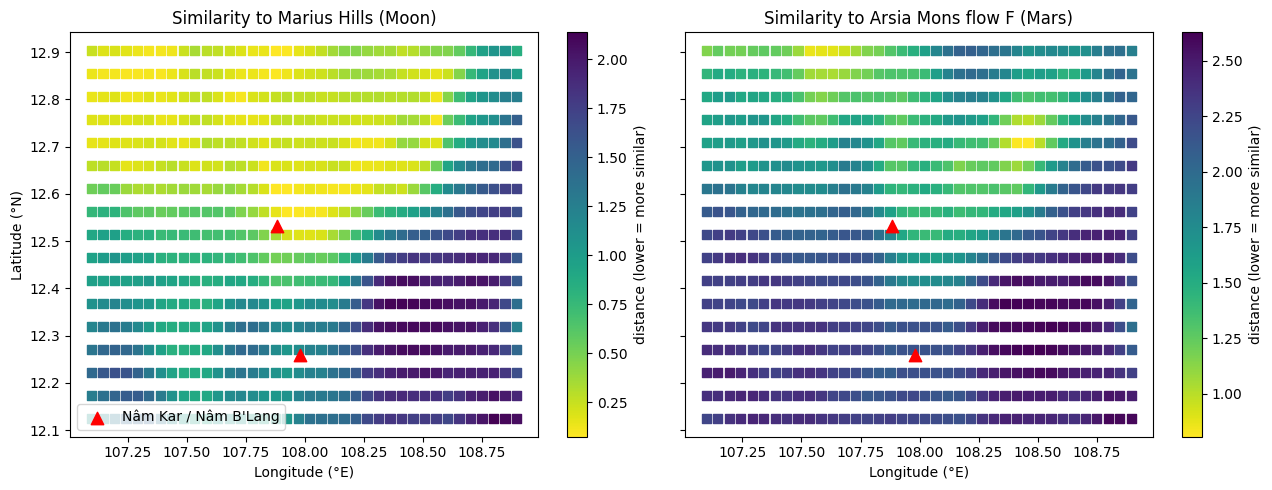

In [44]:
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, col, title in zip(axes, ["d_Moon", "d_Mars"],
                          ["Similarity to Marius Hills (Moon)", "Similarity to Arsia Mons flow F (Mars)"]):
    sc = ax.scatter(scan.lon, scan.lat, c=scan[col], cmap="viridis_r", s=45, marker="s")
    ax.scatter([107.9793, 107.883], [12.2586, 12.533], c="red", marker="^", s=80, label="Nâm Kar / Nâm B'Lang")
    ax.set_title(title)
    ax.set_xlabel("Longitude (°E)")
    plt.colorbar(sc, ax=ax, label="distance (lower = more similar)")
axes[0].set_ylabel("Latitude (°N)")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.savefig("figures/similarity_map.png", dpi=200)
plt.show()

In [45]:
def scan_dem(path, lat_c, F_moon, F_mars, W=100, S=25):
    """Slide a W-pixel window over a DEM; return distance to Moon/Mars features."""
    with rasterio.open(path) as s:
        z0 = s.read(1, masked=True).astype("float64").filled(np.nan)
        rx, ry = s.res
        left, top = s.bounds.left, s.bounds.top
    dx0 = np.radians(rx) * R["earth"] * np.cos(np.radians(lat_c))
    dy0 = np.radians(ry) * R["earth"]
    f = max(1, int(round(200.0 / dx0)))
    z, dx, dy = block_mean(z0, dx0, dy0)
    zf = np.where(np.isnan(z), np.nanmean(z), z)
    gy, gx = np.gradient(zf, dy, dx)
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))
    m, m2 = uniform_filter(zf, 3), uniform_filter(zf**2, 3)
    rough = np.sqrt(np.clip(m2 - m**2, 0, None))
    rows = []
    for i in range(0, slope.shape[0] - W + 1, S):
        for j in range(0, slope.shape[1] - W + 1, S):
            fw = {"slope": slope[i:i+W, j:j+W].ravel(), "rough": rough[i:i+W, j:j+W].ravel()}
            rows.append({"lat": top - (i + W/2) * ry * f,
                         "lon": left + (j + W/2) * rx * f,
                         "mean_elev_m": float(np.nanmean(z[i:i+W, j:j+W])),
                         "d_Moon": dist(fw, F_moon), "d_Mars": dist(fw, F_mars)})
    return pd.DataFrame(rows)

In [46]:
HK = 10  # half-size in km -> 20 x 20 km

z, dx, dy = load_patch("data/LDEM_128.LBL", 14.0917, 303.2299, HK, "moon", lon0=180)
z, dx, dy = block_mean(z, dx, dy)
F_moon20 = features(z, dx, dy)

with rasterio.Env(**ENV):
    z, dx, dy = load_patch(MARS_URL, -3.2, 236.2, HK, "mars", lon0=180)
z, dx, dy = block_mean(z, dx, dy)
F_mars20 = features(z, dx, dy)
print("Moon/Mars 20 km patches ready")

Moon/Mars 20 km patches ready


In [47]:
kn = scan_dem("data/krongno_dem.tif", 12.5, F_moon20, F_mars20)
ct = scan_dem("data/n10e105.hgt", 10.5, F_moon20, F_mars20)

summary = pd.DataFrame({
    "target": ["Marius_Moon", "Arsia_Mars"],
    "KrongNo_best":   [kn.d_Moon.min(),    kn.d_Mars.min()],
    "KrongNo_median": [kn.d_Moon.median(), kn.d_Mars.median()],
    "Control_best":   [ct.d_Moon.min(),    ct.d_Mars.min()],
    "Control_median": [ct.d_Moon.median(), ct.d_Mars.median()],
}).round(3)
print(summary)
print("\nKrông Nô: best 3 windows for Moon")
print(kn.nsmallest(3, "d_Moon").round(3))
print("\nKrông Nô: best 3 windows for Mars")
print(kn.nsmallest(3, "d_Mars").round(3))
scan = kn  # keep the map cell working

        target  KrongNo_best  KrongNo_median  Control_best  Control_median
0  Marius_Moon         0.066           0.861         0.471           0.919
1   Arsia_Mars         0.628           1.332         0.284           0.729

Krông Nô: best 3 windows for Moon
       lat      lon  mean_elev_m  d_Moon  d_Mars
52  12.854  107.778      217.883   0.066   0.813
53  12.854  107.826      226.960   0.073   0.883
51  12.854  107.729      217.906   0.074   0.765

Krông Nô: best 3 windows for Mars
       lat      lon  mean_elev_m  d_Moon  d_Mars
11  12.903  107.632      207.945   0.226   0.628
10  12.903  107.583      210.669   0.245   0.632
12  12.903  107.680      207.653   0.184   0.642


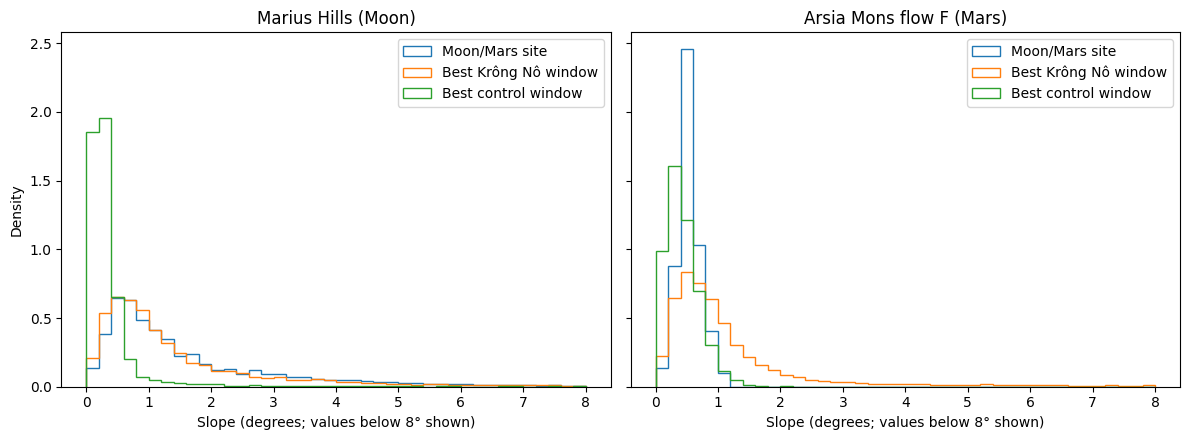

In [50]:
import matplotlib.pyplot as plt

bins = np.linspace(0, 8, 41)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (title, (tgt, k, c)) in zip(axes, panels.items()):
    for f_, lab, ls in [(tgt, "Moon/Mars site", "-"),
                        (k, "Best Krông Nô window", "--"),
                        (c, "Best control window", ":")]:
        ax.hist(f_["slope"][f_["slope"] < 8], bins=bins, density=True,
                histtype="step", lw=2, ls=ls, label=lab)
    ax.set_title(title)
    ax.set_xlabel("Slope (degrees; values below 8° shown)")
    ax.legend()
axes[0].set_ylabel("Density")
plt.tight_layout()
plt.savefig("figures/slope_distributions.png", dpi=200)
plt.show()